# Homework 7

**Course:** MATH 6388

**Author:** Brady Lamson

**Date:** 10/27/2026

---

# Context and Setup

In [13]:
import torch
import torchvision
from torchvision.transforms import v2

# ImageNet standard normalization and resizing
transform = v2.Compose([
    v2.Resize((224, 224)), # Resize CIFAR10 images to fit the pretrained model
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

batch_size = 32

print("Loading Training Set")
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=8)

print("Loading Testing Set")
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=8)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Loading Training Set
Loading Testing Set


In [14]:
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet18, ResNet18_Weights

# 1. Load the pre-trained ResNet18 model
weights = ResNet18_Weights.DEFAULT
net = resnet18(weights=weights)

# 2. Freeze the base layers so we don't destroy the pre-trained features
for param in net.parameters():
    param.requires_grad = False

# 3. Replace the final fully connected layer (fc) to output 10 classes instead of 1000
# By default, new layers have requires_grad=True
num_ftrs = net.fc.in_features
net.fc = nn.Linear(num_ftrs, 10)

# Move model to GPU if available (Pretrained models are larger, GPU helps!)
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
net = net.to(device)

# Define loss and optimizer (only optimizing the new fc layer)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.fc.parameters(), lr=0.001)

In [15]:
print(device)

mps


In [16]:
print(f"Device: {device}")
print(f"Batch size: {trainloader.batch_size}")
print(f"Batches per epoch: {len(trainloader)}")
print(f"Dataset size: {len(trainloader.dataset)}")

Device: mps
Batch size: 32
Batches per epoch: 1563
Dataset size: 50000


In [22]:
import os.path
PATH = './cifar_transfer_net.pt'

if os.path.isfile(PATH):
    print(f"Model found at <{PATH}>, loading model...")
    net.load_state_dict(torch.load(PATH, weights_only=True))
else:
    print(f'Model not found at <{PATH}>, training on {device}...')

    for epoch in range(2):  # loop over the dataset multiple times

        running_loss = 0.0
        for i, data in enumerate(trainloader, 0):
            # get the inputs; data is a list of [inputs, labels]
            inputs, labels = data[0].to(device), data[1].to(device)

            # zero the parameter gradients
            optimizer.zero_grad()

            # forward + backward + optimize
            outputs = net(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            # print statistics
            running_loss += loss.item()
            if i % 200 == 199:    # print every 200 mini-batches
                print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 200:.3f}')
                running_loss = 0.0

    print('Finished Training, saving model')
    torch.save(net.state_dict(), PATH)

Model found at <./cifar_transfer_net.pt>, loading model...


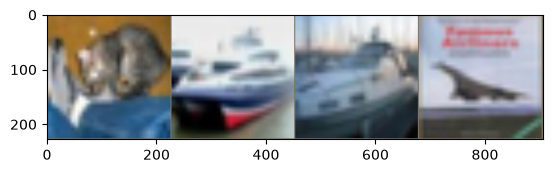

GroundTruth:  cat   ship  ship  plane
Predicted:    cat   car   ship  plane


In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Helper to un-normalize and show images for testing
def imshow(img):
    img = img * torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1) + torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# Get a batch of test data
dataiter = iter(testloader)
images, labels = next(dataiter)

# print images
imshow(torchvision.utils.make_grid(images[:4]))
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

net.eval() # Set to evaluation mode

# Predict
images = images.to(device)
outputs = net(images)
_, predicted = torch.max(outputs, 1)

print('Predicted:   ', ' '.join(f'{classes[predicted[j]]:5s}' for j in range(4)))

In [19]:
correct = 0
total = 0

# Set network to evaluation mode and disable gradient calculation
net.eval()
with torch.no_grad():
    for data in testloader:
        images, labels = data[0].to(device), data[1].to(device)

        # calculate outputs by running images through the network
        outputs = net(images)

        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the pretrained network on the 10000 test images: {100 * correct // total} %')

Accuracy of the pretrained network on the 10000 test images: 69 %


# Homework Problems

The previous cell computes the test accuracy of our adapted network. Now extend this evaluation to investigate **which images the model is most uncertain about**.

Write code to complete the following tasks:

## 1. **Compute predictive entropy for every test image.**
   - Use `net.eval()` and `torch.no_grad()`, as in the previous cell.
   - Apply softmax to the output logits to obtain class probabilities.
   - For each image $\mathbf{x}_i$, calculate
     $$
     H_i=-\sum_{k=1}^{K}
     p_\theta(k\mid\mathbf{x}_i)\log p_\theta(k\mid\mathbf{x}_i).
     $$
   - Store the entropy, image, predicted label, and true label together so they remain correctly matched.
   - Ensure your computation handles probabilities near zero without producing numerical errors.

In [80]:
import polars as pl

def collect_batch_results(batch_index, outputs, labels, batch_size: int):
    probabilities = torch.softmax(outputs, dim=1)
    _, predicted = torch.max(probabilities, 1)
    # torch.special.xlogy calculates plogp - https://docs.pytorch.org/docs/2.14/special.html#torch.special.xlogy
    # It also controls for the case when the input is 0.
    batch_plogp = torch.special.xlogy(probabilities, probabilities)
    batch_entropy = -1 * torch.sum(batch_plogp, dim=1)
    batch_index = torch.full((batch_size,), batch_index)
    within_batch_index = torch.arange(0, batch_size)

    result_dict = {
        "batch_index": batch_index.tolist(),
        "within_batch_index": within_batch_index.tolist(),
        "predicted_label": predicted.tolist(),
        "true_label": labels.tolist(),
        "entropy": batch_entropy.tolist(),
    }
    return pl.from_dict(result_dict)

df = pl.DataFrame()
# Set network to evaluation mode and disable gradient calculation
tinkering = False
# i = 0
net.eval()
with torch.no_grad():
    for i, data in enumerate(testloader):
        if i % 25 == 0:
            print(f"Beginning iteration {i} ---")
        if tinkering and i > 1:
            break

        images, labels = data[0].to(device), data[1].to(device)
        batch_size = len(labels)

        # calculate outputs by running images through the network
        outputs = net(images)
        batch_df = collect_batch_results(batch_index=i, outputs=outputs, labels=labels, batch_size=batch_size)

        if df.is_empty():
            df = batch_df
        else:
            df = pl.union([df, batch_df])

        i += 1

df = df.with_row_index("id")

Beginning iteration 0 ---
Beginning iteration 25 ---
Beginning iteration 50 ---
Beginning iteration 75 ---
Beginning iteration 100 ---
Beginning iteration 125 ---
Beginning iteration 150 ---
Beginning iteration 175 ---
Beginning iteration 200 ---
Beginning iteration 225 ---
Beginning iteration 250 ---
Beginning iteration 275 ---
Beginning iteration 300 ---


In [81]:
print(df)

shape: (10_000, 6)
┌──────┬─────────────┬────────────────────┬─────────────────┬────────────┬──────────┐
│ id   ┆ batch_index ┆ within_batch_index ┆ predicted_label ┆ true_label ┆ entropy  │
│ ---  ┆ ---         ┆ ---                ┆ ---             ┆ ---        ┆ ---      │
│ u32  ┆ i64         ┆ i64                ┆ i64             ┆ i64        ┆ f64      │
╞══════╪═════════════╪════════════════════╪═════════════════╪════════════╪══════════╡
│ 0    ┆ 0           ┆ 0                  ┆ 3               ┆ 3          ┆ 1.689626 │
│ 1    ┆ 0           ┆ 1                  ┆ 1               ┆ 8          ┆ 2.040059 │
│ 2    ┆ 0           ┆ 2                  ┆ 8               ┆ 8          ┆ 1.802814 │
│ 3    ┆ 0           ┆ 3                  ┆ 0               ┆ 0          ┆ 2.108499 │
│ 4    ┆ 0           ┆ 4                  ┆ 6               ┆ 6          ┆ 1.147765 │
│ …    ┆ …           ┆ …                  ┆ …               ┆ …          ┆ …        │
│ 9995 ┆ 312         ┆ 11          

## 2. **Plot the distribution of predictive entropies.**
   - Create a histogram using the entropy values from all test images.
   - Label the horizontal axis **Predictive entropy** and the vertical axis **Number of images**.
   - Recall that entropy ranges from $0$ to $\log K$, where $K$ is the number of classes.

In [97]:
import plotly.express as px
import math

fig = px.histogram(
    df,
    x="entropy",
    labels={"entropy": "Predictive Entropy"}
)
fig.update_layout(yaxis_title="Number of Images")
max_entropy = math.log(10) # 10 classes total for this example
fig.add_vline(x=max_entropy, line_width=3, line_dash="dash", line_color="black", annotation_text="Theoretical max (K=10)", annotation_position="top right")
fig.show()

## 3. **Visualize the 20 images with the highest entropy.**
   - Sort the images by entropy in descending order.
   - Display the top 20 in a **4 × 5 grid**, starting with the highest-entropy image.
   - Above each image, show its entropy, predicted class, and true class.
   - If your preprocessing normalized the images, undo that normalization before displaying them.

**Discussion:** Are the highest-entropy predictions mostly incorrect, or are some correct? What visual characteristics might explain the model's uncertainty? Does high entropy necessarily mean that an image is an outlier?